# 03. Xây dựng và đánh giá mô hình phân loại
Mục tiêu: dự đoán `HeartDisease`. Vì bỏ sót ca bệnh nguy hiểm hơn báo nhầm, **Recall của nhóm có bệnh** được ưu tiên (cùng F1 và ROC-AUC).

In [1]:
import sys; sys.path.append('..')
from src.common import *
import warnings; warnings.filterwarnings('ignore')
import json, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, make_scorer, fbeta_score)
from sklearn.inspection import permutation_importance
df = load_clean(); X, y = df[FEATURES], df[TARGET]

## 1. Chia train/test
Tỷ lệ **80/20**, `stratify=y` để giữ tỷ lệ lớp ở cả hai tập, `random_state=42` để tái lập. Bộ dữ liệu chỉ ~300 dòng nên tập test chỉ ~61 mẫu: kết quả trên test dao động mạnh, vì vậy ta dùng thêm cross-validation 5 fold trên tập train làm bằng chứng chính.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, '| tỷ lệ có bệnh train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

(241, 13) (61, 13) | tỷ lệ có bệnh train/test: 0.456 0.459


## 2. Huấn luyện ba mô hình
Logistic Regression (baseline, `class_weight='balanced'`), Random Forest, Gradient Boosting. Mỗi mô hình nằm trong `Pipeline` cùng bộ tiền xử lý để scaler/imputer chỉ fit trên train.

In [3]:
def pipe(clf): return Pipeline([('prep', make_preprocessor()), ('clf', clf)])
models = {
 'Logistic Regression': pipe(LogisticRegression(max_iter=2000, class_weight='balanced')),
 'Random Forest': pipe(RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE)),
 'Gradient Boosting': pipe(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}
for m in models.values(): m.fit(X_train, y_train)
def metrics(m, Xa, ya):
    p = m.predict(Xa); pr = m.predict_proba(Xa)[:, 1]
    return dict(Accuracy=accuracy_score(ya, p), Precision=precision_score(ya, p), Recall=recall_score(ya, p), F1=f1_score(ya, p), ROC_AUC=roc_auc_score(ya, pr))
train_tab = pd.DataFrame({k: metrics(m, X_train, y_train) for k, m in models.items()}).T.round(3)
test_tab = pd.DataFrame({k: metrics(m, X_test, y_test) for k, m in models.items()}).T.round(3)
print('TRAIN'); display(train_tab); print('TEST'); display(test_tab)

TRAIN


,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.876,0.885,0.836,0.86,0.937
Random Forest,1.000,1.000,1.000,1.00,1.000
Gradient Boosting,1.000,1.000,1.000,1.00,1.000


TEST


,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.836,0.821,0.821,0.821,0.926
Random Forest,0.787,0.800,0.714,0.755,0.889
Gradient Boosting,0.803,0.786,0.786,0.786,0.887


## 3. Đánh giá bằng cross-validation (5 fold, trên tập train)

In [4]:
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
sc = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}
cv_rows = {}
for k, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=skf, scoring=sc, n_jobs=-1)
    cv_rows[k] = {f'{n} (TB)': s['test_'+n].mean() for n in sc} | {'Recall (độ lệch chuẩn)': s['test_recall'].std()}
cv_tab = pd.DataFrame(cv_rows).T.round(3); cv_tab

,accuracy (TB),precision (TB),recall (TB),f1 (TB),roc_auc (TB),Recall (độ lệch chuẩn)
Logistic Regression,0.842,0.840,0.818,0.826,0.903,0.064
Random Forest,0.826,0.826,0.809,0.810,0.904,0.083
Gradient Boosting,0.797,0.780,0.782,0.777,0.873,0.073


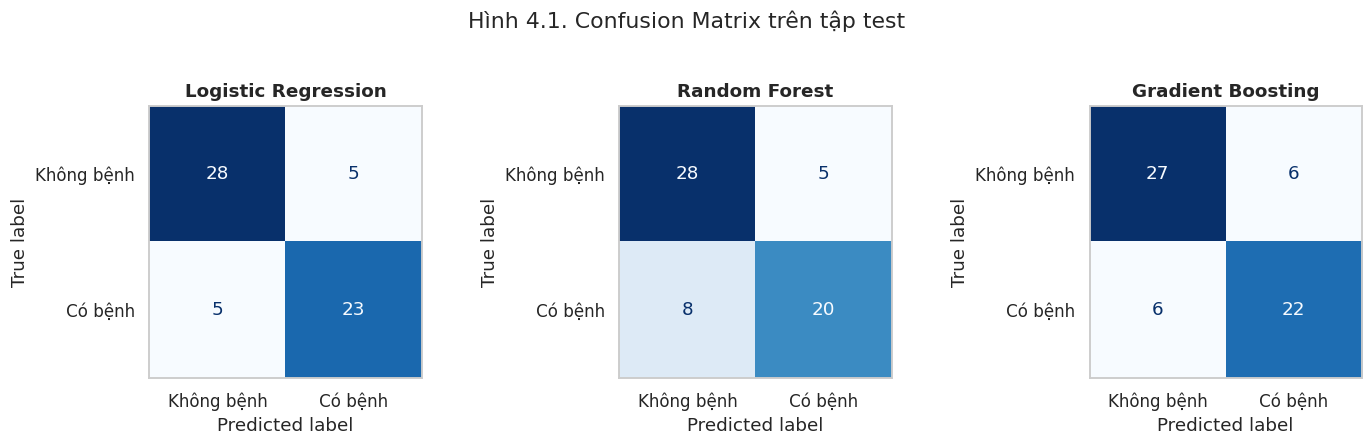

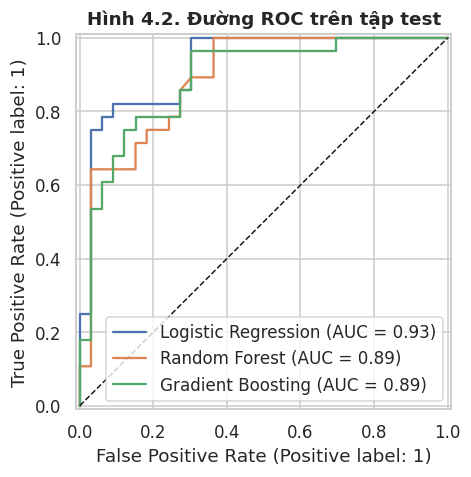

In [5]:
(test_tab.join(cv_tab[['recall (TB)', 'roc_auc (TB)']].rename(columns={'recall (TB)': 'CV Recall', 'roc_auc (TB)': 'CV ROC-AUC'}))).to_csv(ROOT / 'report' / 'bang_so_sanh_3_mo_hinh.csv')
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
for a, (k, m) in zip(ax, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=['Không bệnh', 'Có bệnh'], cmap='Blues', colorbar=False, ax=a)
    a.set_title(k); a.grid(False)
plt.suptitle('Hình 4.1. Confusion Matrix trên tập test', y=1.03)
savefig('fig_4_1_confusion_matrix')
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for k, m in models.items(): RocCurveDisplay.from_estimator(m, X_test, y_test, name=k, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_title('Hình 4.2. Đường ROC trên tập test')
savefig('fig_4_2_roc')

## 4. Tinh chỉnh siêu tham số
`GridSearchCV` 5 fold cho từng mô hình, chọn theo **F2** (đặt trọng số Recall gấp đôi Precision), phù hợp mục tiêu ưu tiên không bỏ sót ca bệnh. Lưới tham số giữ nhỏ vì dữ liệu ít, tránh overfit vào CV.

In [6]:
f2 = make_scorer(fbeta_score, beta=2)
grids = {
 'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10], 'clf__penalty': ['l2']},
 'Random Forest': {'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 5, 8, None], 'clf__min_samples_leaf': [1, 3, 5]},
 'Gradient Boosting': {'clf__n_estimators': [100, 200], 'clf__learning_rate': [0.03, 0.1], 'clf__max_depth': [2, 3]},
}
tuned, rows = {}, []
for k, m in models.items():
    gs = GridSearchCV(m, grids[k], scoring={'f2': f2, 'recall': 'recall', 'roc_auc': 'roc_auc'}, refit='f2', cv=skf, n_jobs=-1).fit(X_train, y_train)
    tuned[k] = gs.best_estimator_
    i = gs.best_index_
    rows.append({'Mô hình': k, 'Tham số tốt nhất': {a.replace('clf__', ''): b for a, b in gs.best_params_.items()},
                 'CV F2': round(gs.cv_results_['mean_test_f2'][i], 3), 'CV Recall': round(gs.cv_results_['mean_test_recall'][i], 3), 'CV ROC-AUC': round(gs.cv_results_['mean_test_roc_auc'][i], 3)})
best_tab = pd.DataFrame(rows); best_tab.to_csv(ROOT / 'report' / 'bang_tham_so_tot_nhat.csv', index=False); best_tab

,Mô hình,Tham số tốt nhất,CV F2,CV Recall,CV ROC-AUC
0,Logistic Regression,"{'C': 0.1, 'penalty': 'l2'}",0.825,0.827,0.908
1,Random Forest,"{'max_depth': 3, 'min_samples_leaf': 3, 'n_est...",0.837,0.845,0.916
2,Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.804,0.809,0.895


In [7]:
tuned_test = pd.DataFrame({k: metrics(m, X_test, y_test) for k, m in tuned.items()}).T.round(3)
tuned_test.to_csv(ROOT / 'report' / 'bang_test_sau_tinh_chinh.csv'); tuned_test

,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.836,0.846,0.786,0.815,0.924
Random Forest,0.803,0.833,0.714,0.769,0.884
Gradient Boosting,0.820,0.870,0.714,0.784,0.893


## 5. Chọn mô hình cuối
Tiêu chí: **CV F2** cao nhất (có xét Recall và ROC-AUC). Không chọn theo kết quả test để tránh "nhìn trộm" tập test.

In [8]:
final_name = best_tab.sort_values(['CV F2', 'CV ROC-AUC'], ascending=False).iloc[0]['Mô hình']
final = tuned[final_name]
print('Mô hình được chọn:', final_name)
print(classification_report(y_test, final.predict(X_test), target_names=['Không bệnh', 'Có bệnh'])) if 'classification_report' in globals() else None
from sklearn.metrics import classification_report
print(classification_report(y_test, final.predict(X_test), target_names=['Không bệnh', 'Có bệnh']))
print(confusion_matrix(y_test, final.predict(X_test)))

Mô hình được chọn: Random Forest
              precision    recall  f1-score   support

  Không bệnh       0.78      0.88      0.83        33
     Có bệnh       0.83      0.71      0.77        28

    accuracy                           0.80        61
   macro avg       0.81      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61

[[29  4]
 [ 8 20]]


## 6. Feature Importance
Dùng **permutation importance** trên tập test của pipeline cuối (đo mức giảm F2 khi xáo trộn một đặc trưng gốc), kết hợp độ quan trọng nội tại của Random Forest để đối chiếu.

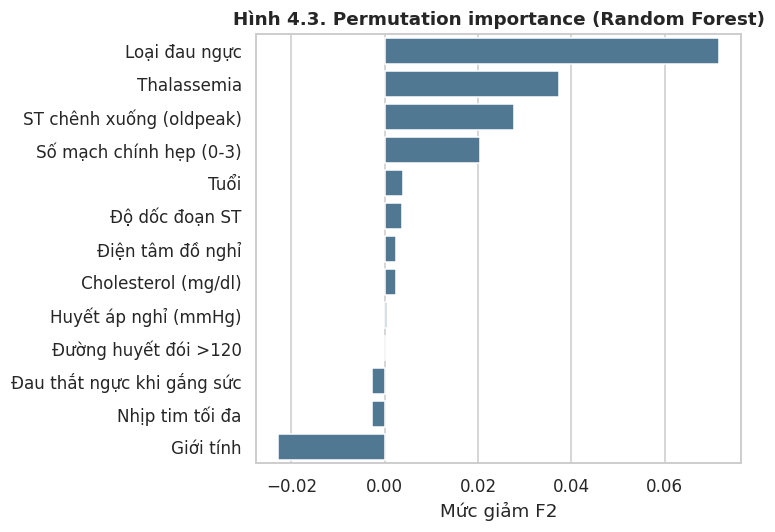

,Đặc trưng,Mức giảm F2,Độ lệch chuẩn,Tên
6,cp,0.0717,0.0284,Loại đau ngực
9,thal,0.0374,0.0651,Thalassemia
4,oldpeak,0.0278,0.0300,ST chênh xuống (oldpeak)
5,ca,0.0204,0.0381,Số mạch chính hẹp (0-3)
0,age,0.0039,0.0041,Tuổi
8,slope,0.0038,0.0224,Độ dốc đoạn ST
7,restecg,0.0025,0.0027,Điện tâm đồ nghỉ
2,chol,0.0023,0.0027,Cholesterol (mg/dl)
1,trestbps,0.0005,0.0016,Huyết áp nghỉ (mmHg)
11,fbs,0.0000,0.0000,Đường huyết đói >120


In [9]:
pi = permutation_importance(final, X_test, y_test, scoring=f2, n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({'Đặc trưng': FEATURES, 'Mức giảm F2': pi.importances_mean, 'Độ lệch chuẩn': pi.importances_std}).sort_values('Mức giảm F2', ascending=False)
imp['Tên'] = imp['Đặc trưng'].map(VN)
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=imp, y='Tên', x='Mức giảm F2', color='#457b9d', ax=ax)
ax.set_title(f'Hình 4.3. Permutation importance ({final_name})'); ax.set_ylabel('')
savefig('fig_4_3_feature_importance')
imp.to_csv(ROOT / 'report' / 'bang_feature_importance.csv', index=False); imp.round(4)

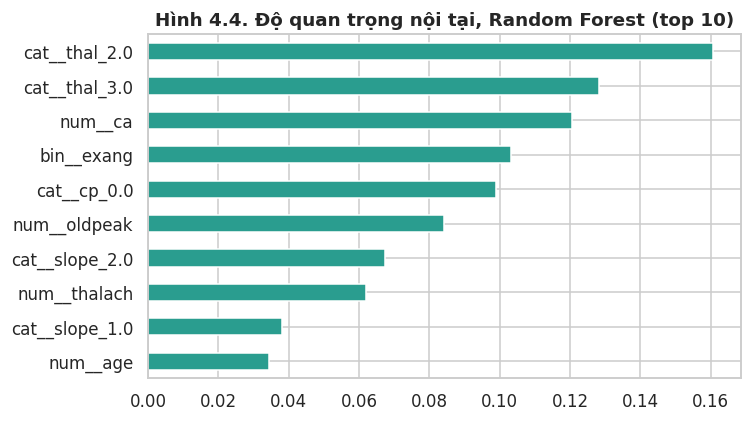

cat__thal_2.0     0.161
cat__thal_3.0     0.128
num__ca           0.121
bin__exang        0.103
cat__cp_0.0       0.099
num__oldpeak      0.084
cat__slope_2.0    0.067
num__thalach      0.062
cat__slope_1.0    0.038
num__age          0.034
dtype: float64

In [10]:
rf = tuned['Random Forest']
names = rf.named_steps['prep'].get_feature_names_out()
rf_imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(7, 4))
rf_imp[::-1].plot.barh(color='#2a9d8f', ax=ax); ax.set_title('Hình 4.4. Độ quan trọng nội tại, Random Forest (top 10)')
savefig('fig_4_4_rf_importance'); rf_imp.round(3)

## 7. Lưu mô hình và kiểm tra nạp lại

In [11]:
meta = {'model': final_name, 'features': FEATURES, 'target': TARGET, 'random_state': RANDOM_STATE,
        'test_metrics': {k: round(float(v), 4) for k, v in metrics(final, X_test, y_test).items()},
        'feature_ranges': {c: [float(df[c].min()), float(df[c].max())] for c in NUMERIC}}
joblib.dump(final, MODELS / 'model.joblib'); json.dump(meta, open(MODELS / 'model_meta.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
reloaded = joblib.load(MODELS / 'model.joblib')
assert np.allclose(reloaded.predict_proba(X_test), final.predict_proba(X_test)), 'Kết quả sau khi nạp lại khác'
print('Nạp lại model.joblib cho kết quả y hệt. Kích thước file (KB):', round((MODELS / 'model.joblib').stat().st_size/1024, 1))
meta['test_metrics']

Nạp lại model.joblib cho kết quả y hệt. Kích thước file (KB): 328.4


{'Accuracy': 0.8033,
 'Precision': 0.8333,
 'Recall': 0.7143,
 'F1': 0.7692,
 'ROC_AUC': 0.8842}